# PolyglotFakeFacts Fresh Training - Transformer Ensemble v7

This notebook trains fresh binary fake/real transformer models on `PolyglotFakeFacts` using the safe v7 setup: core transformer ensemble, TF-IDF baseline, dataset metadata calibrator, tuned threshold, stacked metadata ensemble, and structured report tables.


In [1]:
# Run this setup cell once only if your Jupyter kernel says a package is missing.
%pip install pandas numpy scipy seaborn matplotlib scikit-learn transformers torch tqdm openpyxl


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"

import inspect
import random
import re
import shutil
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 140)


C:\Users\Asus\Downloads\Fake news detection\code\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
GPU: NVIDIA GeForce RTX 2060


In [3]:
PROJECT_DIR = Path(r"C:\Users\Asus\Downloads\Fake news detection\code")
DATA_DIR = PROJECT_DIR / "dataset"

DATASET_SLUG = "polyglotfakefacts"
DATASET_NAME = "PolyglotFakeFacts"
TASK_NAME = "binary"
SPLIT_NAME = "test"

MODEL_OUTPUT_DIR = PROJECT_DIR / "external_trained_models_v7" / DATASET_SLUG
LOGS_DIR = PROJECT_DIR / "external_training_logs_v7" / DATASET_SLUG
SUMMARY_DIR = PROJECT_DIR / "external_summaries_v7" / DATASET_SLUG
for path in [MODEL_OUTPUT_DIR, LOGS_DIR, SUMMARY_DIR]:
    path.mkdir(parents=True, exist_ok=True)

RUN_VERSION = "v7"
print(f"Running notebook version: {RUN_VERSION}")
print(f"Model folder: {MODEL_OUTPUT_DIR}")
print(f"Summary folder: {SUMMARY_DIR}")

BINARY_LABEL_NAMES = ["fake", "real"]
LABEL_TO_ID = {"fake": 0, "real": 1}
ID_TO_LABEL = {0: "fake", 1: "real"}

# Train fresh models for this dataset. Set FORCE_RETRAIN=False after the first full run
# if you want to reuse these dataset-specific models.
TRAIN_MODELS = True
FORCE_RETRAIN = True
USE_CLASS_WEIGHTS = True

DEFAULT_MODELS = [
    "distilbert-base-uncased",
    "bert-base-uncased",
    "roberta-base",
]
OPTIONAL_SLOW_MODELS = ["roberta-large"]

MODEL_CONFIGS = {
    "bert-base-uncased": {"learning_rate": 3e-5, "epochs": 2, "batch_size": 16, "grad_accum": 1, "max_length": 128, "eval_batch_size": 32, "use_safetensors": True},
    "distilbert-base-uncased": {"learning_rate": 3e-5, "epochs": 2, "batch_size": 16, "grad_accum": 1, "max_length": 128, "eval_batch_size": 32, "use_safetensors": True},
    "roberta-base": {"learning_rate": 2e-5, "epochs": 2, "batch_size": 16, "grad_accum": 1, "max_length": 128, "eval_batch_size": 32, "use_safetensors": True},
    "roberta-large": {"learning_rate": 1e-5, "epochs": 2, "batch_size": 2, "grad_accum": 8, "max_length": 128, "eval_batch_size": 4, "use_safetensors": True},
}

# Use None for final research runs. Set a number like 500 or 1000 for quick debugging.
MAX_ROWS_PER_CLASS = None
DROP_DUPLICATE_TEXTS = True
REMOVE_CROSS_SPLIT_DUPLICATES = True
VALID_SIZE = 0.15
TEST_SIZE = 0.15


Running notebook version: v7
Model folder: C:\Users\Asus\Downloads\Fake news detection\code\external_trained_models_v7\polyglotfakefacts
Summary folder: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts


In [4]:
def clean_field(value):
    if pd.isna(value):
        return ""
    text = str(value).strip()
    if text.lower() in {"", "nan", "none", "null", "\\n"}:
        return ""
    return re.sub(r"\s+", " ", text)


def extract_domain(url):
    text = clean_field(url)
    if not text:
        return ""
    candidate = text if "://" in text else "https://" + text
    parsed = urlparse(candidate)
    domain = parsed.netloc or parsed.path.split("/")[0]
    return domain.lower().replace("www.", "")


def limit_rows_per_class(df):
    if MAX_ROWS_PER_CLASS is None:
        return df.reset_index(drop=True)
    limited = (
        df.groupby("label", group_keys=False)
        .apply(lambda part: part.sample(min(len(part), MAX_ROWS_PER_CLASS), random_state=SEED))
        .sample(frac=1, random_state=SEED)
    )
    return limited.reset_index(drop=True)


def split_frame_randomly(df):
    df = df.reset_index(drop=True)
    train_df, temp_df = train_test_split(
        df,
        test_size=VALID_SIZE + TEST_SIZE,
        stratify=df["label"],
        random_state=SEED,
    )
    relative_test_size = TEST_SIZE / (VALID_SIZE + TEST_SIZE)
    valid_df, test_df = train_test_split(
        temp_df,
        test_size=relative_test_size,
        stratify=temp_df["label"],
        random_state=SEED,
    )
    return train_df.reset_index(drop=True), valid_df.reset_index(drop=True), test_df.reset_index(drop=True)


def remove_cross_split_duplicates(train_df, valid_df, test_df):
    train_texts = set(train_df["model_text"])
    valid_df = valid_df[~valid_df["model_text"].isin(train_texts)].copy()
    seen = train_texts | set(valid_df["model_text"])
    test_df = test_df[~test_df["model_text"].isin(seen)].copy()
    return train_df.reset_index(drop=True), valid_df.reset_index(drop=True), test_df.reset_index(drop=True)


def to_split_dict(frame):
    return {
        "texts": frame["model_text"].tolist(),
        "labels": frame["label"].to_numpy(dtype=np.int64),
        "frame": frame.reset_index(drop=True),
    }


def show_split_summary(splits):
    for split_name, split in splits.items():
        labels = pd.Series(split["labels"]).map(ID_TO_LABEL)
        print(f"{split_name}: {len(labels)} rows")
        print(labels.value_counts().reindex(BINARY_LABEL_NAMES, fill_value=0))
        print()


In [5]:
# PolyglotFakeFacts provides an official 80/20 split.
# Use 80.xlsx for training/validation and 20.xlsx for final test.
POLYGLOT_TRAIN_FILE = DATA_DIR / "80.xlsx"
POLYGLOT_TEST_FILE = DATA_DIR / "20.xlsx"


def normalize_column_name(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).strip().lower()).strip("_")


def normalize_label(value, source_file=""):
    text = clean_field(value).lower()
    if text in {"fake", "false", "0", "f"}:
        return LABEL_TO_ID["fake"]
    if text in {"real", "true", "1", "r"}:
        return LABEL_TO_ID["real"]
    lower_file = source_file.lower()
    if "fake" in lower_file:
        return LABEL_TO_ID["fake"]
    if "real" in lower_file:
        return LABEL_TO_ID["real"]
    return np.nan


def build_polyglot_text(row):
    headline = clean_field(row.get("news_headline", ""))
    translated = clean_field(row.get("english_translated_version", ""))
    original = clean_field(row.get("news_original_text", ""))
    keywords = clean_field(row.get("keywords", ""))
    domain = clean_field(row.get("domain", "")) or extract_domain(row.get("url", ""))
    language = clean_field(row.get("language", ""))
    body = translated or original
    parts = []
    if headline:
        parts.append(f"statement: {headline}")
    if body and body.lower() != headline.lower():
        parts.append(f"context: {body[:1800]}")
    if keywords:
        parts.append(f"subject: {keywords}")
    if domain:
        parts.append(f"source domain: {domain}")
    if language:
        parts.append(f"language: {language}")
    return " ".join(parts)


def load_polyglot_split(path):
    df = pd.read_excel(path)
    df.columns = [normalize_column_name(col) for col in df.columns]
    df["source_file"] = path.name
    df["label"] = df["label"].map(lambda value: normalize_label(value, path.name))
    df["label"] = pd.to_numeric(df["label"], errors="coerce")
    df = df.dropna(subset=["label"]).copy()
    df["label"] = df["label"].astype(int)
    df = df[df["label"].isin([0, 1])].copy()
    df["label_name"] = df["label"].map(ID_TO_LABEL)
    df["model_text"] = df.apply(build_polyglot_text, axis=1)
    df = df[df["model_text"].str.len() > 0].copy()
    if DROP_DUPLICATE_TEXTS:
        df = df.drop_duplicates(subset=["model_text"])
    return df.reset_index(drop=True)


def make_dataset_splits():
    train_full_df = load_polyglot_split(POLYGLOT_TRAIN_FILE)
    test_df = load_polyglot_split(POLYGLOT_TEST_FILE)
    train_full_df = limit_rows_per_class(train_full_df)
    train_df, valid_df = train_test_split(
        train_full_df,
        test_size=VALID_SIZE,
        stratify=train_full_df["label"],
        random_state=SEED,
    )
    if REMOVE_CROSS_SPLIT_DUPLICATES:
        train_df, valid_df, test_df = remove_cross_split_duplicates(train_df, valid_df, test_df)
    return {"train": to_split_dict(train_df), "valid": to_split_dict(valid_df), "test": to_split_dict(test_df)}


In [6]:
splits = make_dataset_splits()
show_split_summary(splits)
display(splits["train"]["frame"][["label_name", "model_text", "source_file"]].head())


train: 6259 rows
fake    3340
real    2919
Name: count, dtype: int64

valid: 1105 rows
fake    590
real    515
Name: count, dtype: int64

test: 1801 rows
fake    982
real    819
Name: count, dtype: int64



,label_name,model_text,source_file
0,real,statement: Talviolympialaiset|Olympialaisiin yritettiin tehdä Venäjältä peräisin olleita kyberhyökkäyksiä context: Italy has thwarted cy...,80.xlsx
1,fake,"statement: Gen. broni Mirosław Różański: Szczyt NATO – będzie więcej hałasu niż konkretów context: Why is the government ""closing"" count...",80.xlsx
2,real,"statement: La guerra en Ucrania agrava la crisis demográfica de Rusia context: One demographer estimates that some 150,000 people, most ...",80.xlsx
3,fake,statement: Las fuerzas armadas de Rusia señalan la presencia de biolaboratorios financiados por Estados Unidos en Nigeria en medio del s...,80.xlsx
4,real,"statement: 'Lo siento, declaré la III Guerra Mundial'"""" context: Liberals and Greens wanted to push Chancellor Olaf Scholz to completely...",80.xlsx


In [7]:
def make_compute_metrics(task_name, label_names):
    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        return {
            "accuracy": accuracy_score(labels, preds),
            "macro_recall": recall_score(labels, preds, average="macro", zero_division=0),
            "weighted_recall": recall_score(labels, preds, average="weighted", zero_division=0),
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
            "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0),
            "fake_recall": recall_score(labels, preds, pos_label=0, zero_division=0),
            "real_recall": recall_score(labels, preds, pos_label=1, zero_division=0),
        }
    return compute_metrics


def summarize_predictions(y_true, y_pred, method):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1],
        zero_division=0,
    )
    return {
        "dataset": DATASET_NAME,
        "task": TASK_NAME,
        "split": SPLIT_NAME,
        "method": method,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "fake_precision": precision[0],
        "fake_recall": recall[0],
        "fake_f1": f1[0],
        "fake_support": int(support[0]),
        "real_precision": precision[1],
        "real_recall": recall[1],
        "real_f1": f1[1],
        "real_support": int(support[1]),
    }


In [8]:
class FakeNewsDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = [int(x) for x in labels]

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


class WeightedLossTrainer(Trainer):
    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weights = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = torch.nn.CrossEntropyLoss(weight=weights)
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def encode_texts(tokenizer, texts, labels, max_length=128):
    encodings = tokenizer(texts, truncation=True, max_length=max_length)
    return FakeNewsDataset(encodings, labels)


def model_safe_name(model_name):
    return model_name.replace("/", "_").replace("-", "_").replace(".", "_")


def local_model_ready(path):
    path = Path(path)
    model_file_exists = (path / "model.safetensors").exists() or (path / "pytorch_model.bin").exists()
    tokenizer_exists = any((path / name).exists() for name in ["tokenizer.json", "vocab.txt", "merges.txt", "sentencepiece.bpe.model", "spiece.model", "spm.model"])
    return (path / "config.json").exists() and model_file_exists and tokenizer_exists


def get_class_weights(labels, num_labels):
    classes = np.arange(num_labels)
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=np.asarray(labels))
    return torch.tensor(weights, dtype=torch.float32)


def cleanup_checkpoints(run_dir):
    run_dir = Path(run_dir)
    for checkpoint_dir in run_dir.glob("checkpoint-*"):
        if checkpoint_dir.is_dir():
            shutil.rmtree(checkpoint_dir, ignore_errors=True)


def make_training_arguments(**kwargs):
    supported = set(inspect.signature(TrainingArguments.__init__).parameters)
    args = dict(kwargs)
    if "eval_strategy" in args and "eval_strategy" not in supported and "evaluation_strategy" in supported:
        args["evaluation_strategy"] = args.pop("eval_strategy")
    filtered = {key: value for key, value in args.items() if key in supported}
    skipped = sorted(set(args) - supported)
    if skipped:
        print("Skipping unsupported TrainingArguments:", skipped)
    return TrainingArguments(**filtered)


def build_trainer(**kwargs):
    supported = set(inspect.signature(Trainer.__init__).parameters)
    tokenizer = kwargs.pop("tokenizer")
    if "processing_class" in supported:
        kwargs["processing_class"] = tokenizer
    elif "tokenizer" in supported:
        kwargs["tokenizer"] = tokenizer
    return WeightedLossTrainer(**kwargs)


def estimate_warmup_steps(num_examples, batch_size, grad_accum, epochs):
    effective_batch = max(1, batch_size * grad_accum)
    steps_per_epoch = max(1, int(np.ceil(num_examples / effective_batch)))
    total_steps = max(1, steps_per_epoch * int(np.ceil(epochs)))
    return min(100, max(0, int(0.10 * total_steps)))


def train_or_load_transformer(model_name, splits, force_retrain=False, use_class_weights=True):
    config = MODEL_CONFIGS[model_name]
    run_dir = MODEL_OUTPUT_DIR / f"{model_safe_name(model_name)}_binary"
    if force_retrain and run_dir.exists():
        shutil.rmtree(run_dir, ignore_errors=True)
    run_dir.mkdir(parents=True, exist_ok=True)

    source = str(run_dir) if local_model_ready(run_dir) and not force_retrain else model_name
    if source == str(run_dir):
        print(f"Loading existing {DATASET_NAME} model: {run_dir}")
    else:
        print(f"Training fresh {model_name} on {DATASET_NAME} -> {run_dir}")

    tokenizer = AutoTokenizer.from_pretrained(source)
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    train_dataset = encode_texts(tokenizer, splits["train"]["texts"], splits["train"]["labels"], config["max_length"])
    valid_dataset = encode_texts(tokenizer, splits["valid"]["texts"], splits["valid"]["labels"], config["max_length"])

    id2label = {i: name for i, name in enumerate(BINARY_LABEL_NAMES)}
    label2id = {name: i for i, name in id2label.items()}
    model_kwargs = {"num_labels": len(BINARY_LABEL_NAMES), "id2label": id2label, "label2id": label2id, "ignore_mismatched_sizes": True}
    if config.get("use_safetensors"):
        model_kwargs["use_safetensors"] = True
    model = AutoModelForSequenceClassification.from_pretrained(source, **model_kwargs)

    warmup_steps = estimate_warmup_steps(
        len(splits["train"]["labels"]),
        config["batch_size"],
        config.get("grad_accum", 1),
        config["epochs"],
    )
    training_args = make_training_arguments(
        output_dir=str(run_dir),
        logging_dir=str(LOGS_DIR / model_safe_name(model_name)),
        do_train=True,
        do_eval=True,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_macro_f1",
        greater_is_better=True,
        per_device_train_batch_size=config["batch_size"],
        per_device_eval_batch_size=config.get("eval_batch_size", 32),
        gradient_accumulation_steps=config.get("grad_accum", 1),
        learning_rate=config["learning_rate"],
        num_train_epochs=config["epochs"],
        weight_decay=0.01,
        warmup_steps=warmup_steps,
        logging_steps=50,
        save_total_limit=1,
        save_only_model=True,
        seed=SEED,
        data_seed=SEED,
        report_to="none",
        fp16=torch.cuda.is_available(),
    )

    class_weights = get_class_weights(splits["train"]["labels"], len(BINARY_LABEL_NAMES)) if use_class_weights else None
    trainer = build_trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=valid_dataset,
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=make_compute_metrics(TASK_NAME, BINARY_LABEL_NAMES),
        class_weights=class_weights,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    if source != str(run_dir):
        trainer.train()
        trainer.save_model(str(run_dir))
        tokenizer.save_pretrained(str(run_dir))
        cleanup_checkpoints(run_dir)

    valid_metrics = trainer.evaluate(valid_dataset)
    print(f"\n{model_name} validation metrics")
    print(pd.Series(valid_metrics).filter(like="eval_").round(4).to_string())
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "model_name": model_name,
        "run_dir": run_dir,
        "valid_metrics": valid_metrics,
        "max_length": config["max_length"],
        "eval_batch_size": config.get("eval_batch_size", 32),
    }


In [9]:
trained_artifacts = []
if TRAIN_MODELS:
    for model_name in DEFAULT_MODELS:
        artifact = train_or_load_transformer(
            model_name,
            splits,
            force_retrain=FORCE_RETRAIN,
            use_class_weights=USE_CLASS_WEIGHTS,
        )
        trained_artifacts.append(artifact)
else:
    for model_name in DEFAULT_MODELS:
        run_dir = MODEL_OUTPUT_DIR / f"{model_safe_name(model_name)}_binary"
        if local_model_ready(run_dir):
            trained_artifacts.append({
                "model_name": model_name,
                "run_dir": run_dir,
                "max_length": MODEL_CONFIGS[model_name]["max_length"],
                "eval_batch_size": MODEL_CONFIGS[model_name].get("eval_batch_size", 32),
            })
        else:
            print(f"Missing saved model: {run_dir}")

trained_artifacts


Training fresh distilbert-base-uncased on PolyglotFakeFacts -> C:\Users\Asus\Downloads\Fake news detection\code\external_trained_models_v7\polyglotfakefacts\distilbert_base_uncased_binary


Loading weights: 100%|█████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 5262.68it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOG

Epoch,Training Loss,Validation Loss,Accuracy,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Fake Recall,Real Recall
1,0.152281,0.132189,0.952941,0.954081,0.952941,0.952833,0.952986,0.937288,0.970874
2,0.069208,0.136021,0.966516,0.966669,0.966516,0.966381,0.966525,0.964407,0.968932


Writing model shards: 100%|██████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.53it/s]


Training Loss,Validation Loss,Epoch,Accuracy,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Fake Recall,Real Recall
0.069208,0.136021,2,0.966516,0.966669,0.966516,0.966381,0.966525,0.964407,0.968932


...

Epoch,Training Loss,Validation Loss,Accuracy,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Fake Recall,Real Recall
1,0.242750,0.165302,0.947511,0.947268,0.947511,0.947268,0.947511,0.950847,0.943689
2,0.117778,0.167649,0.952036,0.951999,0.952036,0.951832,0.952045,0.952542,0.951456


Writing model shards: 100%|██████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.33it/s]


Training Loss,Validation Loss,Epoch,Accuracy,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Fake Recall,Real Recall
0.117778,0.167649,2,0.952036,0.951999,0.952036,0.951832,0.952045,0.952542,0.951456



roberta-base validation metrics
eval_loss               0.1676
eval_accuracy           0.9520
eval_macro_recall       0.9520
eval_weighted_recall    0.9520
eval_macro_f1           0.9518
eval_weighted_f1        0.9520
eval_fake_recall        0.9525
eval_real_recall        0.9515


[{'model_name': 'distilbert-base-uncased',
  'run_dir': WindowsPath('C:/Users/Asus/Downloads/Fake news detection/code/external_trained_models_v7/polyglotfakefacts/distilbert_base_uncased_binary'),
  'valid_metrics': {'eval_loss': 0.136020690202713,
   'eval_accuracy': 0.9665158371040724,
   'eval_macro_recall': 0.9666694092479842,
   'eval_weighted_recall': 0.9665158371040724,
   'eval_macro_f1': 0.9663809230136704,
   'eval_weighted_f1': 0.9665254738248152,
   'eval_fake_recall': 0.964406779661017,
   'eval_real_recall': 0.9689320388349515},
  'max_length': 128,
  'eval_batch_size': 32},
 {'model_name': 'bert-base-uncased',
  'run_dir': WindowsPath('C:/Users/Asus/Downloads/Fake news detection/code/external_trained_models_v7/polyglotfakefacts/bert_base_uncased_binary'),
  'valid_metrics': {'eval_loss': 0.1347985416650772,
   'eval_accuracy': 0.9665158371040724,
   'eval_macro_recall': 0.9670396577258515,
   'eval_weighted_recall': 0.9665158371040724,
   'eval_macro_f1': 0.9664031344474

In [10]:
def predict_probabilities(model_dir, texts, max_length=128, batch_size=16):
    model_dir = Path(model_dir)
    tokenizer = AutoTokenizer.from_pretrained(str(model_dir), local_files_only=True)
    model = AutoModelForSequenceClassification.from_pretrained(str(model_dir), local_files_only=True).to(device)
    model.eval()
    if not torch.cuda.is_available():
        batch_size = min(batch_size, 8)
    all_probs = []
    for start in tqdm(range(0, len(texts), batch_size), desc=model_dir.name):
        batch_texts = texts[start:start + batch_size]
        inputs = tokenizer(batch_texts, return_tensors="pt", padding=True, truncation=True, max_length=max_length).to(device)
        with torch.inference_mode():
            logits = model(**inputs).logits
            probs = torch.softmax(logits, dim=-1).detach().cpu().numpy()
        all_probs.append(probs)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return np.vstack(all_probs)



def artifact_probability_key(artifact):
    return f"{artifact['model_name']} [{DATASET_SLUG}]"


def collect_probabilities(artifacts, split_name):
    prob_dict = {}
    texts = splits[split_name]["texts"]
    for artifact in artifacts:
        key = artifact_probability_key(artifact)
        prob_dict[key] = predict_probabilities(
            artifact["run_dir"],
            texts,
            max_length=artifact["max_length"],
            batch_size=artifact["eval_batch_size"],
        )
    return prob_dict


valid_probabilities = collect_probabilities(trained_artifacts, "valid")
test_probabilities = collect_probabilities(trained_artifacts, "test")
y_valid = splits["valid"]["labels"]
y_test = splits["test"]["labels"]


roberta_base_binary: 100%|█████████████████████████████████████████████████████████████| 57/57 [00:23<00:00,  2.45it/s]


In [11]:
def majority_vote(prob_dict):
    model_names = list(prob_dict)
    pred_stack = np.column_stack([np.argmax(prob_dict[name], axis=1) for name in model_names])
    avg_probs = np.mean([prob_dict[name] for name in model_names], axis=0)
    final_preds = []
    for row_idx, row in enumerate(pred_stack):
        counts = np.bincount(row, minlength=len(BINARY_LABEL_NAMES))
        winners = np.flatnonzero(counts == counts.max())
        final_preds.append(int(winners[0] if len(winners) == 1 else winners[np.argmax(avg_probs[row_idx, winners])]))
    return np.array(final_preds, dtype=np.int64), avg_probs


def averaged_probability_vote(prob_dict):
    avg_probs = np.mean(list(prob_dict.values()), axis=0)
    return np.argmax(avg_probs, axis=1).astype(np.int64), avg_probs


def validation_weighted_probability_vote(valid_prob_dict, test_prob_dict, y_valid):
    model_names = list(test_prob_dict)
    weights = np.array([
        f1_score(y_valid, np.argmax(valid_prob_dict[name], axis=1), average="macro", zero_division=0)
        for name in model_names
    ], dtype=float)
    if not np.isfinite(weights).all() or weights.sum() <= 0:
        weights = np.ones(len(model_names), dtype=float)
    weights = weights / weights.sum()
    stacked = np.stack([test_prob_dict[name] for name in model_names], axis=0)
    avg_probs = np.tensordot(weights, stacked, axes=(0, 0))
    return np.argmax(avg_probs, axis=1).astype(np.int64), avg_probs, dict(zip(model_names, weights))


def tune_binary_fake_threshold(fake_scores, y_true, min_fake_recall=None, optimize_for="accuracy"):
    rows = []
    for threshold in np.linspace(0.05, 0.95, 181):
        preds = np.where(fake_scores >= threshold, 0, 1)
        rows.append({
            "threshold": float(threshold),
            "accuracy": accuracy_score(y_true, preds),
            "macro_recall": recall_score(y_true, preds, average="macro", zero_division=0),
            "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
            "fake_recall": recall_score(y_true, preds, pos_label=0, zero_division=0),
            "real_recall": recall_score(y_true, preds, pos_label=1, zero_division=0),
        })
    table = pd.DataFrame(rows)
    candidates = table
    if min_fake_recall is not None:
        eligible = table[table["fake_recall"] >= min_fake_recall].copy()
        if len(eligible):
            candidates = eligible
    sort_cols = [optimize_for, "macro_f1", "macro_recall", "accuracy"]
    sort_cols = [col for col in sort_cols if col in candidates.columns]
    best = candidates.sort_values(sort_cols, ascending=False).iloc[0]
    return best, table


def train_tfidf_baseline(splits):
    vectorizer = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), max_features=50000, min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=50000, min_df=2, sublinear_tf=True)),
    ])
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0, n_jobs=-1, random_state=SEED)
    X_train = vectorizer.fit_transform(splits["train"]["texts"])
    clf.fit(X_train, splits["train"]["labels"])
    valid_probs = clf.predict_proba(vectorizer.transform(splits["valid"]["texts"]))
    test_probs = clf.predict_proba(vectorizer.transform(splits["test"]["texts"]))
    return clf, vectorizer, valid_probs, test_probs


DATASET_METADATA_CANDIDATES = [
    "domain",
    "source_file",
    "language",
    "keywords",
    "news_source",
    "source",
    "publisher",
]


def metadata_columns_for_frame(frame):
    return [col for col in DATASET_METADATA_CANDIDATES if col in frame.columns]


def fit_smoothed_target_encoding(frame, labels, columns, alpha=30.0):
    labels = np.asarray(labels, dtype=int)
    prior = np.bincount(labels, minlength=len(BINARY_LABEL_NAMES)).astype(float)
    prior = prior / np.maximum(prior.sum(), 1.0)
    encoders = {}
    for column in columns:
        keys = frame[column].fillna("").astype(str).map(clean_field)
        table = {}
        for key, label in zip(keys, labels):
            bucket = table.setdefault(key, np.zeros(len(BINARY_LABEL_NAMES), dtype=float))
            bucket[label] += 1.0
        encoders[column] = {
            key: (counts + alpha * prior) / (counts.sum() + alpha)
            for key, counts in table.items()
        }
    return {"prior": prior, "encoders": encoders, "columns": list(columns)}


def transform_smoothed_target_encoding(frame, fitted):
    prior = fitted["prior"]
    parts = []
    for column in fitted["columns"]:
        mapping = fitted["encoders"][column]
        keys = frame[column].fillna("").astype(str).map(clean_field)
        parts.append(np.vstack([mapping.get(key, prior) for key in keys]))
    if not parts:
        return np.empty((len(frame), 0), dtype=float)
    return np.hstack(parts)


def metadata_numeric_features(frame):
    text_lengths = frame["model_text"].fillna("").astype(str).str.split().str.len().to_numpy(dtype=float).reshape(-1, 1)
    source_lengths = frame.get("source_file", pd.Series([""] * len(frame))).fillna("").astype(str).str.len().to_numpy(dtype=float).reshape(-1, 1)
    domain_lengths = frame.get("domain", pd.Series([""] * len(frame))).fillna("").astype(str).str.len().to_numpy(dtype=float).reshape(-1, 1)
    return np.hstack([text_lengths, source_lengths, domain_lengths])


def train_dataset_metadata_baseline(splits):
    columns = metadata_columns_for_frame(splits["train"]["frame"])
    fitted = fit_smoothed_target_encoding(splits["train"]["frame"], splits["train"]["labels"], columns)
    x_train = np.hstack([
        transform_smoothed_target_encoding(splits["train"]["frame"], fitted),
        metadata_numeric_features(splits["train"]["frame"]),
    ])
    x_valid = np.hstack([
        transform_smoothed_target_encoding(splits["valid"]["frame"], fitted),
        metadata_numeric_features(splits["valid"]["frame"]),
    ])
    x_test = np.hstack([
        transform_smoothed_target_encoding(splits["test"]["frame"], fitted),
        metadata_numeric_features(splits["test"]["frame"]),
    ])
    scaler = StandardScaler()
    x_train = scaler.fit_transform(x_train)
    x_valid = scaler.transform(x_valid)
    x_test = scaler.transform(x_test)
    clf = LogisticRegression(max_iter=3000, class_weight="balanced", C=2.0, random_state=SEED)
    clf.fit(x_train, splits["train"]["labels"])
    return clf, scaler, fitted, clf.predict_proba(x_valid), clf.predict_proba(x_test)


def stacked_meta_ensemble(valid_prob_dict, test_prob_dict, baseline_valid_probs, baseline_test_probs, metadata_valid_probs, metadata_test_probs, y_valid):
    valid_parts = [valid_prob_dict[name] for name in valid_prob_dict] + [baseline_valid_probs]
    test_parts = [test_prob_dict[name] for name in test_prob_dict] + [baseline_test_probs]
    if metadata_valid_probs is not None and metadata_test_probs is not None:
        valid_parts.append(metadata_valid_probs)
        test_parts.append(metadata_test_probs)
    valid_features = np.hstack(valid_parts)
    test_features = np.hstack(test_parts)
    meta = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0, random_state=SEED)
    meta.fit(valid_features, y_valid)
    return meta.predict(test_features).astype(np.int64), meta.predict_proba(test_features), meta


In [12]:
summary_rows = []
predictions_by_method = {}

for model_name, probs in test_probabilities.items():
    preds = np.argmax(probs, axis=1).astype(np.int64)
    method = f"Individual: {model_name}"
    predictions_by_method[method] = preds
    summary_rows.append(summarize_predictions(y_test, preds, method))

baseline_model, baseline_vectorizer, baseline_valid_probs, baseline_test_probs = train_tfidf_baseline(splits)
baseline_preds = np.argmax(baseline_test_probs, axis=1).astype(np.int64)
predictions_by_method["Baseline: TF-IDF"] = baseline_preds
summary_rows.append(summarize_predictions(y_test, baseline_preds, "Baseline: TF-IDF"))

metadata_model, metadata_scaler, metadata_encoder, metadata_valid_probs, metadata_test_probs = train_dataset_metadata_baseline(splits)
metadata_preds = np.argmax(metadata_test_probs, axis=1).astype(np.int64)
predictions_by_method["Baseline: dataset metadata"] = metadata_preds
summary_rows.append(summarize_predictions(y_test, metadata_preds, "Baseline: dataset metadata"))

majority_preds, _ = majority_vote(test_probabilities)
_, avg_valid_probs = averaged_probability_vote(valid_probabilities)
avg_test_preds, avg_test_probs = averaged_probability_vote(test_probabilities)
weighted_preds, weighted_test_probs, model_weights = validation_weighted_probability_vote(valid_probabilities, test_probabilities, y_valid)
best_threshold, threshold_table = tune_binary_fake_threshold(avg_valid_probs[:, 0], y_valid, min_fake_recall=None, optimize_for="accuracy")
threshold_preds = np.where(avg_test_probs[:, 0] >= best_threshold["threshold"], 0, 1).astype(np.int64)
stacked_preds, stacked_probs, stacked_model = stacked_meta_ensemble(
    valid_probabilities,
    test_probabilities,
    baseline_valid_probs,
    baseline_test_probs,
    metadata_valid_probs,
    metadata_test_probs,
    y_valid,
)

ensemble_outputs = {
    "Ensemble: majority vote": majority_preds,
    "Ensemble: highest-sum / avg prob": avg_test_preds,
    "Ensemble: validation-weighted avg prob": weighted_preds,
    "Ensemble: tuned accuracy threshold": threshold_preds,
    "Ensemble: stacked transformer + metadata meta": stacked_preds,
}
for method, preds in ensemble_outputs.items():
    predictions_by_method[method] = preds
    summary_rows.append(summarize_predictions(y_test, preds, method))

summary_table = pd.DataFrame(summary_rows).round(4)
summary_table = summary_table.sort_values(["accuracy", "macro_f1"], ascending=False).reset_index(drop=True)
summary_path = SUMMARY_DIR / "binary_results_table.csv"
summary_table.to_csv(summary_path, index=False)
threshold_path = SUMMARY_DIR / "threshold_tuning_table.csv"
threshold_table.round(4).to_csv(threshold_path, index=False)
weights_path = SUMMARY_DIR / "validation_model_weights.csv"
pd.Series(model_weights, name="validation_macro_f1_weight").to_csv(weights_path)

print("Binary result table")
display(summary_table)
if len(summary_table):
    best_row = summary_table.iloc[0]
    best_accuracy = float(best_row["accuracy"])
    if best_accuracy >= 0.80:
        print(f"\nBINARY TARGET REACHED: {best_accuracy:.4f} accuracy using {best_row['method']}")
    else:
        print(f"\nBinary best is {best_accuracy:.4f}; gap to 0.8000 is {0.80 - best_accuracy:.4f}.")
print("\nBest validation threshold for accuracy")
display(best_threshold.round(4).to_frame().T)
print("\nValidation-derived ensemble weights")
display(pd.Series(model_weights, name="weight").round(4).to_frame())
print("Saved:", summary_path)
print("Saved:", threshold_path)
print("Saved:", weights_path)


Binary result table


,dataset,task,split,method,accuracy,macro_recall,weighted_recall,macro_f1,weighted_f1,fake_precision,fake_recall,fake_f1,fake_support,real_precision,real_recall,real_f1,real_support
0,PolyglotFakeFacts,binary,test,Ensemble: stacked transformer + metadata meta,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,982,1.0000,1.0000,1.0000,819
1,PolyglotFakeFacts,binary,test,Baseline: dataset metadata,0.9994,0.9995,0.9994,0.9994,0.9994,1.0000,0.9990,0.9995,982,0.9988,1.0000,0.9994,819
2,PolyglotFakeFacts,binary,test,Baseline: TF-IDF,0.9961,0.9962,0.9961,0.9961,0.9961,0.9980,0.9949,0.9964,982,0.9939,0.9976,0.9957,819
3,PolyglotFakeFacts,binary,test,Ensemble: tuned accuracy threshold,0.9717,0.9703,0.9717,0.9714,0.9716,0.9632,0.9857,0.9743,982,0.9824,0.9548,0.9684,819
4,PolyglotFakeFacts,binary,test,Ensemble: majority vote,0.9711,0.9700,0.9711,0.9708,0.9711,0.9650,0.9827,0.9738,982,0.9788,0.9573,0.9679,819
5,PolyglotFakeFacts,binary,test,Ensemble: highest-sum / avg prob,0.9711,0.9700,0.9711,0.9708,0.9711,0.9650,0.9827,0.9738,982,0.9788,0.9573,0.9679,819
6,PolyglotFakeFacts,binary,test,Ensemble: validation-weighted avg prob,0.9706,0.9695,0.9706,0.9703,0.9705,0.9650,0.9817,0.9732,982,0.9776,0.9573,0.9673,819
7,PolyglotFakeFacts,binary,test,Individual: bert-base-uncased [polyglotfakefacts],0.9650,0.9648,0.9650,0.9647,0.9650,0.9684,0.9674,0.9679,982,0.9610,0.9621,0.9616,819
8,PolyglotFakeFacts,binary,test,Individual: roberta-base [polyglotfakefacts],0.9628,0.9619,0.9628,0.9624,0.9628,0.9607,0.9715,0.9661,982,0.9653,0.9524,0.9588,819
9,PolyglotFakeFacts,binary,test,Individual: distilbert-base-uncased [polyglotfakefacts],0.9622,0.9606,0.9622,0.9618,0.9622,0.9534,0.9786,0.9658,982,0.9735,0.9426,0.9578,819



BINARY TARGET REACHED: 1.0000 accuracy using Ensemble: stacked transformer + metadata meta

Best validation threshold for accuracy


,threshold,accuracy,macro_recall,macro_f1,fake_recall,real_recall
68,0.39,0.9729,0.9727,0.9727,0.9746,0.9709



Validation-derived ensemble weights


,weight
distilbert-base-uncased [polyglotfakefacts],0.335
bert-base-uncased [polyglotfakefacts],0.335
roberta-base [polyglotfakefacts],0.330


Saved: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\binary_results_table.csv
Saved: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\threshold_tuning_table.csv
Saved: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\validation_model_weights.csv


Per-class long table


,dataset,split,method,class,precision,recall,f1_score,support
0,PolyglotFakeFacts,test,Individual: distilbert-base-uncased [polyglotfakefacts],fake,0.9534,0.9786,0.9658,982
1,PolyglotFakeFacts,test,Individual: distilbert-base-uncased [polyglotfakefacts],real,0.9735,0.9426,0.9578,819
2,PolyglotFakeFacts,test,Individual: bert-base-uncased [polyglotfakefacts],fake,0.9684,0.9674,0.9679,982
3,PolyglotFakeFacts,test,Individual: bert-base-uncased [polyglotfakefacts],real,0.9610,0.9621,0.9616,819
4,PolyglotFakeFacts,test,Individual: roberta-base [polyglotfakefacts],fake,0.9607,0.9715,0.9661,982
5,PolyglotFakeFacts,test,Individual: roberta-base [polyglotfakefacts],real,0.9653,0.9524,0.9588,819
6,PolyglotFakeFacts,test,Baseline: TF-IDF,fake,0.9980,0.9949,0.9964,982
7,PolyglotFakeFacts,test,Baseline: TF-IDF,real,0.9939,0.9976,0.9957,819
8,PolyglotFakeFacts,test,Baseline: dataset metadata,fake,1.0000,0.9990,0.9995,982
9,PolyglotFakeFacts,test,Baseline: dataset metadata,real,0.9988,1.0000,0.9994,819



Per-class recall by method


method,Baseline: TF-IDF,Baseline: dataset metadata,Ensemble: highest-sum / avg prob,Ensemble: majority vote,Ensemble: stacked transformer + metadata meta,Ensemble: tuned accuracy threshold,Ensemble: validation-weighted avg prob,Individual: bert-base-uncased [polyglotfakefacts],Individual: distilbert-base-uncased [polyglotfakefacts],Individual: roberta-base [polyglotfakefacts]
class,,,,,,,,,,
fake,0.9949,0.999,0.9827,0.9827,1.0,0.9857,0.9817,0.9674,0.9786,0.9715
real,0.9976,1.000,0.9573,0.9573,1.0,0.9548,0.9573,0.9621,0.9426,0.9524



Per-class precision by method


method,Baseline: TF-IDF,Baseline: dataset metadata,Ensemble: highest-sum / avg prob,Ensemble: majority vote,Ensemble: stacked transformer + metadata meta,Ensemble: tuned accuracy threshold,Ensemble: validation-weighted avg prob,Individual: bert-base-uncased [polyglotfakefacts],Individual: distilbert-base-uncased [polyglotfakefacts],Individual: roberta-base [polyglotfakefacts]
class,,,,,,,,,,
fake,0.9980,1.0000,0.9650,0.9650,1.0,0.9632,0.9650,0.9684,0.9534,0.9607
real,0.9939,0.9988,0.9788,0.9788,1.0,0.9824,0.9776,0.9610,0.9735,0.9653



Per-class F1 by method


method,Baseline: TF-IDF,Baseline: dataset metadata,Ensemble: highest-sum / avg prob,Ensemble: majority vote,Ensemble: stacked transformer + metadata meta,Ensemble: tuned accuracy threshold,Ensemble: validation-weighted avg prob,Individual: bert-base-uncased [polyglotfakefacts],Individual: distilbert-base-uncased [polyglotfakefacts],Individual: roberta-base [polyglotfakefacts]
class,,,,,,,,,,
fake,0.9964,0.9995,0.9738,0.9738,1.0,0.9743,0.9732,0.9679,0.9658,0.9661
real,0.9957,0.9994,0.9679,0.9679,1.0,0.9684,0.9673,0.9616,0.9578,0.9588


Saved: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\binary_per_class_report_long.csv
Saved: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\binary_per_class_recall_wide.csv
Saved: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\binary_per_class_precision_wide.csv
Saved: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\binary_per_class_f1_wide.csv


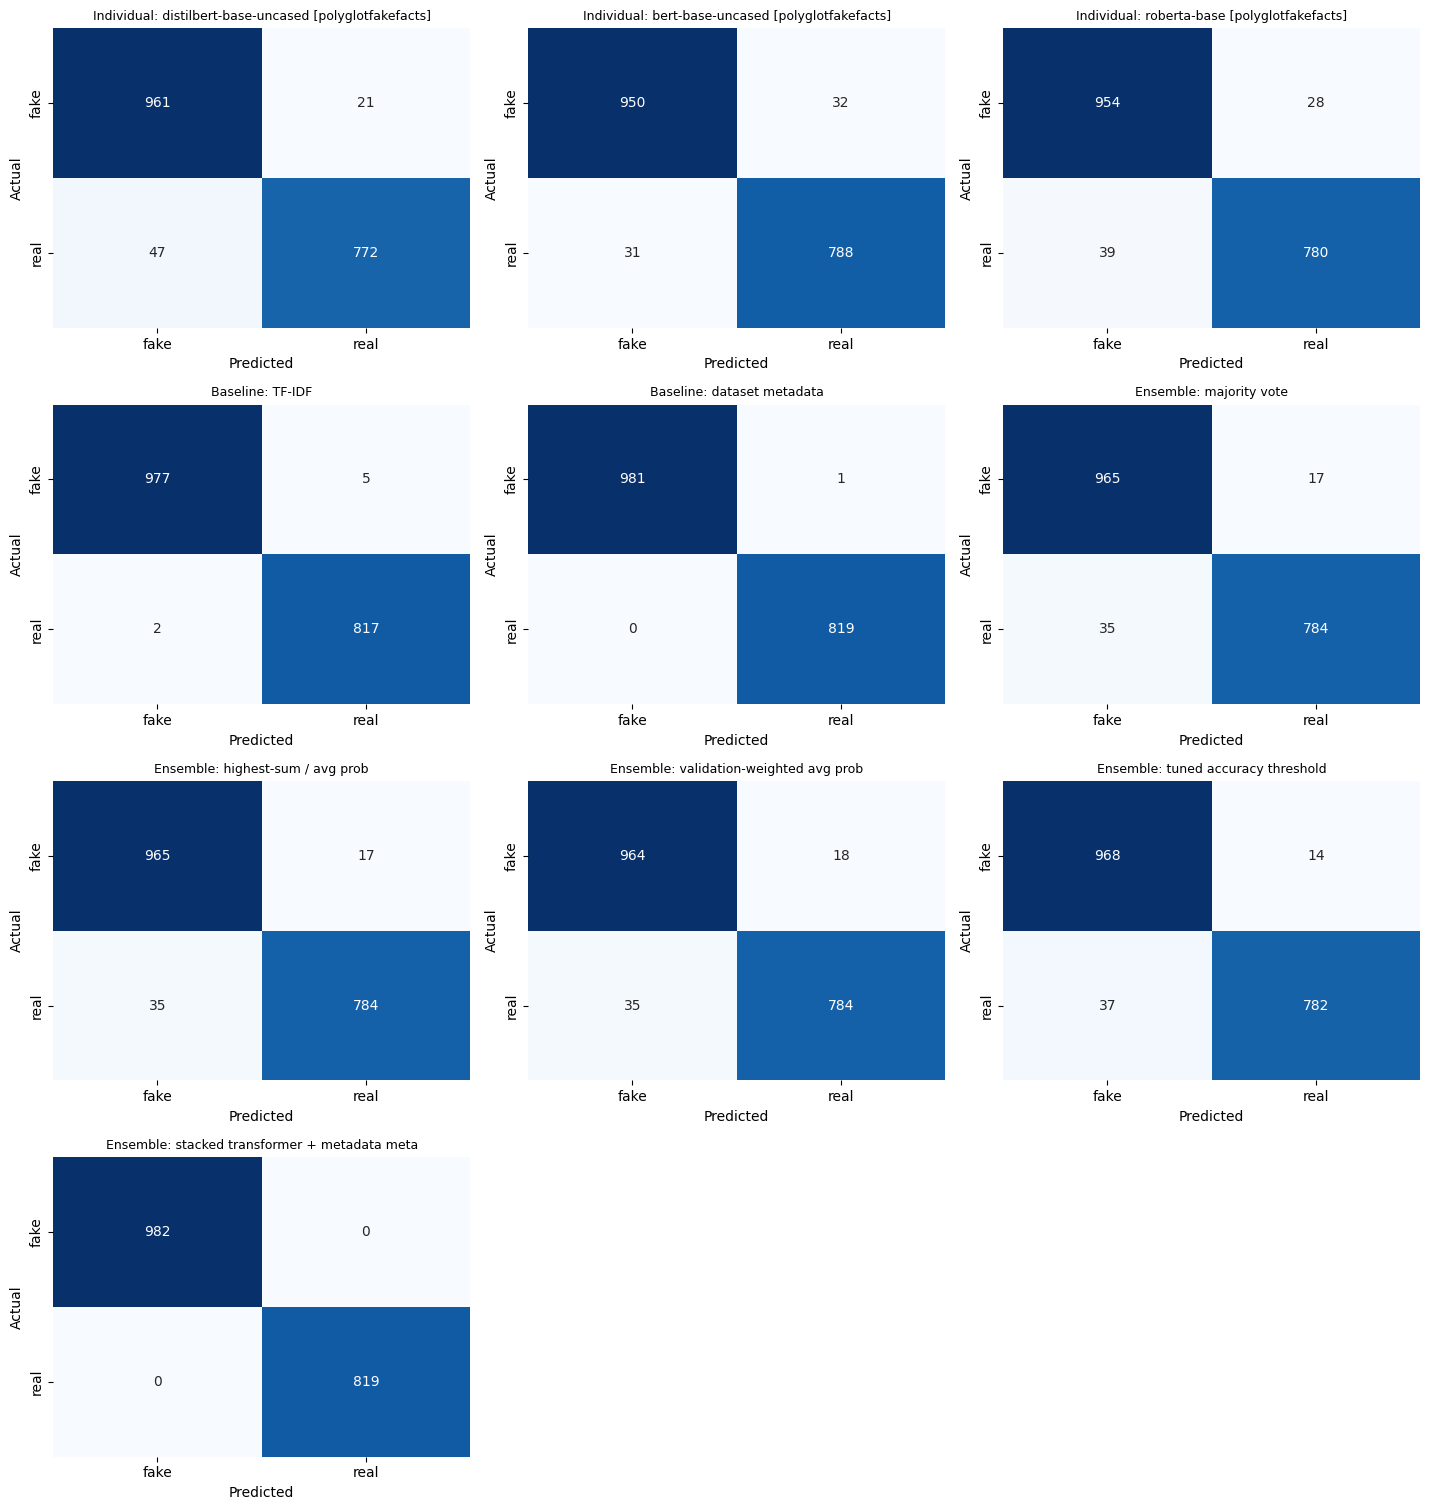

In [13]:
def per_class_long_table(y_true, prediction_dict):
    rows = []
    for method, preds in prediction_dict.items():
        report = classification_report(
            y_true,
            preds,
            labels=[0, 1],
            target_names=BINARY_LABEL_NAMES,
            output_dict=True,
            zero_division=0,
        )
        for label_name in BINARY_LABEL_NAMES:
            rows.append({
                "dataset": DATASET_NAME,
                "split": SPLIT_NAME,
                "method": method,
                "class": label_name,
                "precision": report[label_name]["precision"],
                "recall": report[label_name]["recall"],
                "f1_score": report[label_name]["f1-score"],
                "support": int(report[label_name]["support"]),
            })
    return pd.DataFrame(rows)


def make_wide_metric_table(per_class_df, metric):
    return per_class_df.pivot(index="class", columns="method", values=metric).reindex(BINARY_LABEL_NAMES).round(4)


def plot_confusion_matrices(y_true, prediction_dict):
    methods = list(prediction_dict)
    cols = 3
    rows = int(np.ceil(len(methods) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.8 * cols, 3.8 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, method in zip(axes, methods):
        cm = confusion_matrix(y_true, prediction_dict[method], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BINARY_LABEL_NAMES, yticklabels=BINARY_LABEL_NAMES, ax=ax, cbar=False)
        ax.set_title(method, fontsize=9)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    for ax in axes[len(methods):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


per_class_df = per_class_long_table(y_test, predictions_by_method).round(4)
per_class_path = SUMMARY_DIR / "binary_per_class_report_long.csv"
per_class_df.to_csv(per_class_path, index=False)

recall_wide = make_wide_metric_table(per_class_df, "recall")
precision_wide = make_wide_metric_table(per_class_df, "precision")
f1_wide = make_wide_metric_table(per_class_df, "f1_score")

recall_path = SUMMARY_DIR / "binary_per_class_recall_wide.csv"
precision_path = SUMMARY_DIR / "binary_per_class_precision_wide.csv"
f1_path = SUMMARY_DIR / "binary_per_class_f1_wide.csv"
recall_wide.to_csv(recall_path)
precision_wide.to_csv(precision_path)
f1_wide.to_csv(f1_path)

print("Per-class long table")
display(per_class_df)
print("\nPer-class recall by method")
display(recall_wide)
print("\nPer-class precision by method")
display(precision_wide)
print("\nPer-class F1 by method")
display(f1_wide)
print("Saved:", per_class_path)
print("Saved:", recall_path)
print("Saved:", precision_path)
print("Saved:", f1_path)

plot_confusion_matrices(y_test, predictions_by_method)


In [14]:
def safe_column_name(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:80]


base_columns = [col for col in ["label", "label_name", "model_text", "source_file"] if col in splits["test"]["frame"].columns]
prediction_export = splits["test"]["frame"][base_columns].copy()
for model_name, probs in test_probabilities.items():
    safe = safe_column_name(model_name)
    prediction_export[f"{safe}_prob_fake"] = probs[:, 0]
    prediction_export[f"{safe}_prob_real"] = probs[:, 1]
    prediction_export[f"{safe}_pred"] = np.argmax(probs, axis=1)

prediction_export["baseline_tfidf_prob_fake"] = baseline_test_probs[:, 0]
prediction_export["baseline_tfidf_prob_real"] = baseline_test_probs[:, 1]
prediction_export["baseline_metadata_prob_fake"] = metadata_test_probs[:, 0]
prediction_export["baseline_metadata_prob_real"] = metadata_test_probs[:, 1]
prediction_export["avg_prob_fake"] = avg_test_probs[:, 0]
prediction_export["avg_prob_real"] = avg_test_probs[:, 1]
prediction_export["stacked_prob_fake"] = stacked_probs[:, 0]
prediction_export["stacked_prob_real"] = stacked_probs[:, 1]

for method, preds in predictions_by_method.items():
    safe = safe_column_name(method)
    prediction_export[f"pred_{safe}"] = preds
    prediction_export[f"pred_label_{safe}"] = [ID_TO_LABEL[int(x)] for x in preds]

prediction_path = SUMMARY_DIR / "binary_test_predictions.csv"
prediction_export.to_csv(prediction_path, index=False)
print("Saved predictions:", prediction_path)
display(prediction_export.head())


Saved predictions: C:\Users\Asus\Downloads\Fake news detection\code\external_summaries_v7\polyglotfakefacts\binary_test_predictions.csv


,label,label_name,model_text,source_file,distilbert_base_uncased_polyglotfakefacts_prob_fake,distilbert_base_uncased_polyglotfakefacts_prob_real,distilbert_base_uncased_polyglotfakefacts_pred,bert_base_uncased_polyglotfakefacts_prob_fake,bert_base_uncased_polyglotfakefacts_prob_real,bert_base_uncased_polyglotfakefacts_pred,roberta_base_polyglotfakefacts_prob_fake,roberta_base_polyglotfakefacts_prob_real,roberta_base_polyglotfakefacts_pred,baseline_tfidf_prob_fake,baseline_tfidf_prob_real,baseline_metadata_prob_fake,baseline_metadata_prob_real,avg_prob_fake,avg_prob_real,stacked_prob_fake,stacked_prob_real,pred_individual_distilbert_base_uncased_polyglotfakefacts,pred_label_individual_distilbert_base_uncased_polyglotfakefacts,pred_individual_bert_base_uncased_polyglotfakefacts,pred_label_individual_bert_base_uncased_polyglotfakefacts,pred_individual_roberta_base_polyglotfakefacts,pred_label_individual_roberta_base_polyglotfakefacts,pred_baseline_tf_idf,pred_label_baseline_tf_idf,pred_baseline_dataset_metadata,pred_label_baseline_dataset_metadata,pred_ensemble_majority_vote,pred_label_ensemble_majority_vote,pred_ensemble_highest_sum_avg_prob,pred_label_ensemble_highest_sum_avg_prob,pred_ensemble_validation_weighted_avg_prob,pred_label_ensemble_validation_weighted_avg_prob,pred_ensemble_tuned_accuracy_threshold,pred_label_ensemble_tuned_accuracy_threshold,pred_ensemble_stacked_transformer_metadata_meta,pred_label_ensemble_stacked_transformer_metadata_meta
0,1,real,"statement: من إدارة القطاع إلى إدارة الفراغ.. هل تحوِّل إسرائيل غزة إلى ""ضفة أخرى""؟ context: Since the announcement of the formation of ...",20.xlsx,0.043308,0.956693,1,0.002574,0.997426,1,0.014539,0.985460,1,0.101464,0.898536,0.001983,0.998017,0.020140,0.979860,0.003910,0.996090,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real
1,1,real,statement: Abschlussbericht zum Sturm aufs US-Kapitol: Trump war an „mehrteiligem Komplott“ beteiligt context: Donald TrumpNow the ex-US...,20.xlsx,0.001576,0.998424,1,0.000362,0.999638,1,0.000809,0.999191,1,0.161237,0.838763,0.000013,0.999987,0.000916,0.999084,0.004630,0.995370,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real
2,1,real,"statement: V Maskatu skončily schůzky v rámci jaderných rozhovorů mezi USA a Íránem context: Muscat - A series of meetings in Muscat, Om...",20.xlsx,0.002587,0.997413,1,0.003380,0.996620,1,0.001589,0.998411,1,0.053551,0.946449,0.001438,0.998562,0.002518,0.997482,0.003130,0.996870,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real
3,0,fake,statement: Guerre des médias et censure: la Lettonie interdit à RT de diffuser 7 de ses chaînes context: RT saw seven such channels bann...,20.xlsx,0.995788,0.004212,0,0.998476,0.001524,0,0.998324,0.001676,0,0.978030,0.021970,0.999877,0.000123,0.997529,0.002471,0.997655,0.002345,0,fake,0,fake,0,fake,0,fake,0,fake,0,fake,0,fake,0,fake,0,fake,0,fake
4,1,real,"statement: Yhdysvallat|Televisio­juontajan äiti katosi, mediat kertovat saaneensa kirjeitä lunnas­vaatimuksista context: Nancy Guthrie, ...",20.xlsx,0.001741,0.998259,1,0.000249,0.999751,1,0.000915,0.999085,1,0.058119,0.941881,0.000005,0.999995,0.000968,0.999032,0.003142,0.996858,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real,1,real


## Outputs For Report

Use these files from this notebook's dataset folder under `external_summaries_v7`:

- `binary_results_table.csv`: individual transformers, TF-IDF baseline, dataset metadata baseline, and ensemble methods.
- `threshold_tuning_table.csv`: validation threshold search for the averaged-probability ensemble.
- `validation_model_weights.csv`: validation-derived weights for the weighted ensemble.
- `binary_per_class_report_long.csv`: precision, recall, F1, and support for fake and real for each method.
- `binary_per_class_recall_wide.csv`, `binary_per_class_precision_wide.csv`, `binary_per_class_f1_wide.csv`: compact report-friendly tables.
- `binary_test_predictions.csv`: test examples with probabilities and predicted labels.

Fresh transformer models are saved under `external_trained_models_v7/<dataset_name>/`.
